# 02 · Redistribución de liquidez

$M = -\alpha I - D_0 L + \beta W$, $L = D_\text{out} - W$. El término $-D_0Lx$ traslada presión sin crearla.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "axes.grid": True,
                     "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
TOPO_LABEL = {"erdos_renyi": "Erdős–Rényi", "barabasi_albert": "Barabási–Albert",
              "core_periphery": "Núcleo-periferia"}

In [2]:
from pulso.networks import NetworkConfig, generate

def_cfg = dict(n=120, mean_degree=6.0, amount_sigma=0.8, core_frac=0.1, p_core=0.8,
               periphery_share=0.1, seed=1)
nets = {t: generate(NetworkConfig(topology=t, **def_cfg)) for t in TOPO_LABEL}

## Conservación con $\alpha=\beta=0$

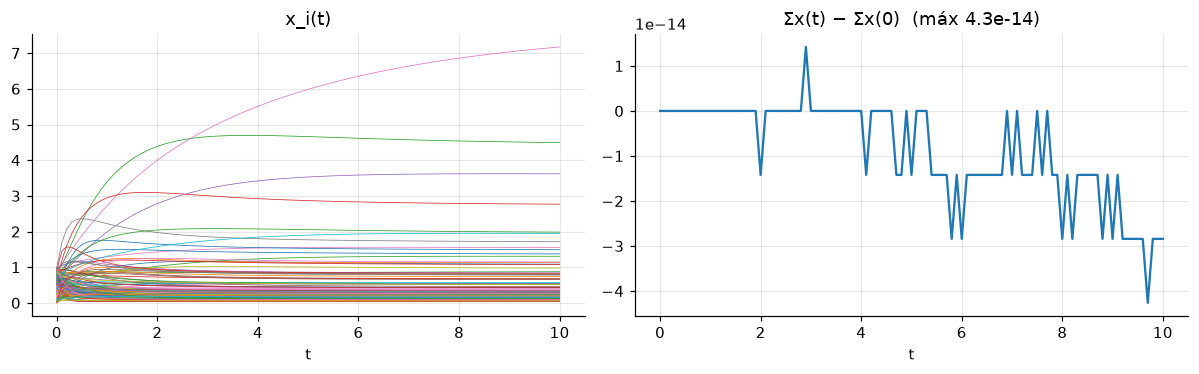

In [3]:
from pulso.integrate import simulate
from pulso.model import Params

W = nets["erdos_renyi"]
x0 = np.random.default_rng(0).random(W.shape[0])
traj = simulate(W, Params(alpha=0, beta=0, D0=1.0), t_end=10, dt=0.01, x0=x0, save_every=10)
err = np.abs(traj.x.sum(1) - x0.sum()).max()
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].plot(traj.t, traj.x, lw=0.5); ax[0].set(title="x_i(t)", xlabel="t")
ax[1].plot(traj.t, traj.x.sum(1) - x0.sum()); ax[1].set(title=f"Σx(t) − Σx(0)  (máx {err:.1e})", xlabel="t")
fig.tight_layout(); fig.savefig(FIG / "fase2_conservacion.png")

## $\tau_\text{rec}$ contra $\lambda_2$ por topología
Con $\beta = 0$ y $\alpha$ pequeño, la recuperación la domina la redistribución: más conectividad algebraica, recuperación más rápida (no aplica al modo uniforme, que decae a tasa α; aquí medimos el modo más lento ortogonal a él).

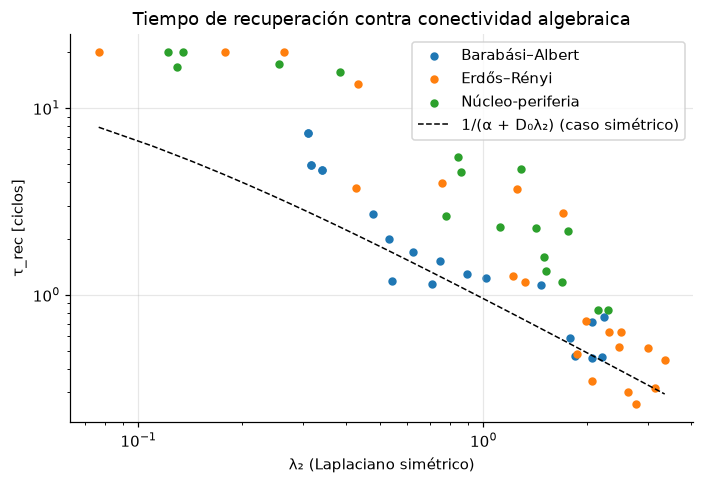

In [4]:
from pulso.spectral import algebraic_connectivity, flow_laplacian, symmetric_laplacian

rows = []
for t in TOPO_LABEL:
    for k in np.linspace(3, 14, 7):
        for s in range(3):
            W = generate(NetworkConfig(topology=t, **{**def_cfg, "mean_degree": k, "seed": s}))
            lam2 = algebraic_connectivity(W)
            if lam2 < 1e-8:  # red desconectada: λ2 = 0 y no hay modo de recuperación único
                continue
            # Modo más lento de -D0 L restringido al complemento del vector nulo
            ev = np.sort(np.linalg.eigvals(flow_laplacian(W)).real)
            rate = 0.05 + 1.0 * ev[1]
            rows.append({"topologia": TOPO_LABEL[t], "lambda2": lam2, "tau_rec": 1 / rate})
df = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(6.5, 4.5))
for t, g in df.groupby("topologia"):
    ax.scatter(g["lambda2"], g["tau_rec"], label=t, s=20)
lam = np.linspace(df.lambda2.min(), df.lambda2.max(), 100)
ax.plot(lam, 1 / (0.05 + lam), "k--", lw=1, label="1/(α + D₀λ₂) (caso simétrico)")
ax.set(xlabel="λ₂ (Laplaciano simétrico)", ylabel="τ_rec [ciclos]", xscale="log", yscale="log",
       title="Tiempo de recuperación contra conectividad algebraica")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "fase2_tau_vs_lambda2.png")

## Comunidades (bisección espectral de Fiedler)

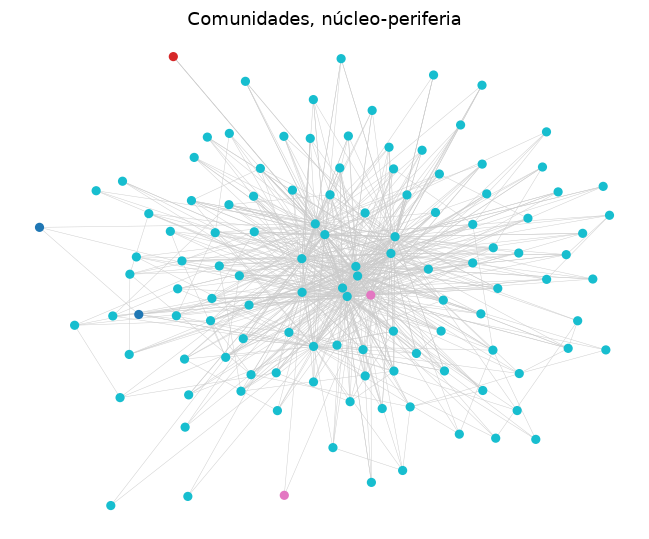

In [5]:
from pulso.service import layout
from pulso.spectral import communities

W = nets["core_periphery"]
lab = communities(W, n_communities=4)
pos = layout(W, seed=0)
fig, ax = plt.subplots(figsize=(6, 5))
rows_, cols_ = np.nonzero(W)
ax.plot(np.c_[pos[cols_, 0], pos[rows_, 0]].T, np.c_[pos[cols_, 1], pos[rows_, 1]].T, c="0.8", lw=0.3)
ax.scatter(pos[:, 0], pos[:, 1], c=lab, cmap="tab10", s=25, zorder=3)
ax.set_axis_off(); ax.set_title("Comunidades, núcleo-periferia")
fig.tight_layout(); fig.savefig(FIG / "fase2_comunidades.png")

## Cómo $D_0$ desplaza el umbral de estabilidad
$\sigma$ contra $R$ para varios $D_0$. En redes dirigidas heterogéneas la redistribución mueve la frontera.

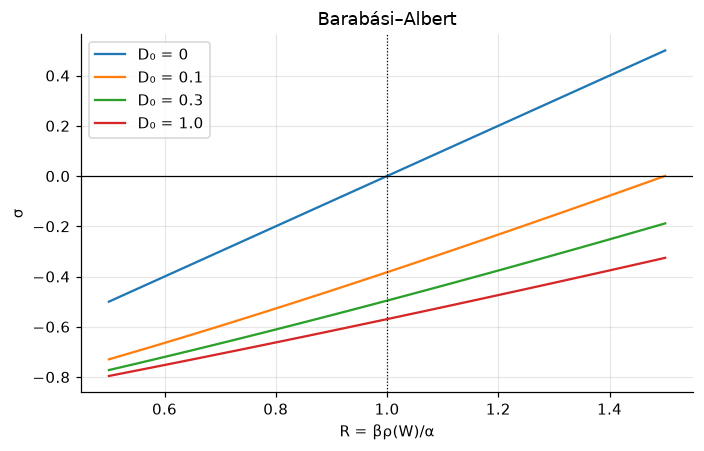

In [6]:
from pulso.spectral import perron_root, stability

W = nets["barabasi_albert"]; rho = perron_root(W)
Rs = np.linspace(0.5, 1.5, 41)
fig, ax = plt.subplots(figsize=(6.5, 4.2))
for D0 in [0, 0.1, 0.3, 1.0]:
    ax.plot(Rs, [stability(W, Params(alpha=1, beta=R / rho, D0=D0)) for R in Rs], label=f"D₀ = {D0}")
ax.axhline(0, c="k", lw=0.8); ax.axvline(1, c="k", lw=0.8, ls=":")
ax.set(xlabel="R = βρ(W)/α", ylabel="σ", title="Barabási–Albert"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "fase2_D0_umbral.png")